# Phase 6a-ter — L'expérience de contrôle

En 6a-bis, on a changé **deux choses à la fois** : on a retiré les doublons **et** on a fait 4,5 fois moins d'étapes (1 492 contre 6 806). Le nouveau modèle récite moins mais répond moins bien : est-ce à cause du dédoublonnage, ou juste d'un entraînement trop court ?

Pour séparer les deux effets, on garde les **données dédoublonnées** et on fait varier **une seule chose** : le nombre d'époques. Un entraînement de **4 époques**, avec une mesure complète **à la fin de chaque époque** :
- la **perte de validation** (sur la validation dédoublonnée, donc propre) ;
- le **taux de recopie** (8-grammes copiés du jeu d'entraînement) ;
- le **taux de répétition** : la part de la réponse où le modèle se répète lui-même (« de la taille de l'objet, de la taille de l'objet… »).

Si plus d'époques améliore les réponses sans faire remonter la recopie, le dédoublonnage est sain. Si la recopie remonte, on saura à partir de quand.

**Kaggle :** GPU T4 x2, Internet On, token Hugging Face demandé. Compte une vingtaine de minutes (estimation).

In [11]:
!pip -q install tokenizers safetensors huggingface_hub
import os, sys, json, math, time, random, re, copy
from collections import Counter, defaultdict
from getpass import getpass
import numpy as np, torch, torch.nn.functional as F
from huggingface_hub import hf_hub_download, login, HfApi
from safetensors.torch import load_model, save_model
from tokenizers import Tokenizer

login(token=getpass("Token Hugging Face (Write) : "))

TRAVAIL = "/kaggle/working"
BASE, INSTRUCT = "Ezeck01/petit-gpt-fr-46m", "Ezeck01/petit-gpt-fr-46m-instruct"

# La v1 n'est plus la version actuelle du dépôt : on la retrouve dans l'historique.
commits = HfApi().list_repo_commits(INSTRUCT)
v1 = next(c for c in commits if c.title.startswith("SFT sur French-Alpaca"))
print("Version v1 retrouvée dans l'historique :", v1.commit_id[:8], "|", v1.title)

for f in ["model.py", "config.json", "model.safetensors"]:
    hf_hub_download(BASE, f, local_dir=f"{TRAVAIL}/base")
for f in ["config.json", "tokenizer.json", "model.safetensors"]:
    hf_hub_download(INSTRUCT, f, revision=v1.commit_id, local_dir=f"{TRAVAIL}/v1")
sys.path.append(f"{TRAVAIL}/base")
from model import Config, GPT

device = "cuda"
print("GPU :", torch.cuda.get_device_name(0))

ancien = GPT(Config(**json.load(open(f"{TRAVAIL}/v1/config.json"))))
load_model(ancien, f"{TRAVAIL}/v1/model.safetensors")
ancien.to(device).eval()
config = ancien.config
tokenizer = Tokenizer.from_file(f"{TRAVAIL}/v1/tokenizer.json")
ID_UTIL, ID_ASSIST, ID_FIN = (tokenizer.token_to_id(t) for t in ("<|utilisateur|>", "<|assistant|>", "<|endoftext|>"))

chemin = hf_hub_download("jpacifico/French-Alpaca-dataset-Instruct-110K",
                         "Acquiesce_data_110k_instructions.json", repo_type="dataset", local_dir=TRAVAIL)
donnees = json.load(open(chemin, encoding="utf-8"))
print(f"{len(donnees):,} exemples")

Token Hugging Face (Write) :  ········


Version v1 retrouvée dans l'historique : 45785735 | SFT sur French-Alpaca


config.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.15M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  186MB            

model.safetensors: downloading bytes:           |  0.00B            

GPU : Tesla T4
110,368 exemples


## 1. Les mêmes données dédoublonnées qu'en 6a-bis

Même code, même graine aléatoire : on retrouve **exactement** le même dédoublonnage et la même séparation train / validation. C'est indispensable pour que la comparaison soit juste.

In [12]:
def normaliser(texte):
    return re.sub(r"[^\w\s]", " ", texte.lower()).split()

groupes = defaultdict(list)
for ex in donnees:
    groupes[" ".join(normaliser(ex["output"])[:10])].append(ex)

random.seed(0)
gardes = [random.choice(g) for g in groupes.values()]

def formater(ex):
    demande = ex["instruction"] + (("\n\n" + ex["input"]) if ex["input"] else "")
    return demande.strip(), ex["output"].strip()

def encoder(demande, reponse=None):
    ids = [ID_UTIL] + tokenizer.encode("\n" + demande + "\n").ids + [ID_ASSIST] + tokenizer.encode("\n").ids
    if reponse is None:
        return ids
    ids_reponse = tokenizer.encode(reponse).ids + [ID_FIN]
    return ids + ids_reponse, [-100] * len(ids) + ids_reponse

exemples = []
for ex in gardes:
    demande, reponse = formater(ex)
    if not reponse or "```" in reponse or "def " in reponse:
        continue
    ids, cibles = encoder(demande, reponse)
    if len(ids) <= config.block_size:
        exemples.append((ids, cibles, ex))
random.shuffle(exemples)
val_ex, train_ex = exemples[:1000], exemples[1000:]
print(f"Train : {len(train_ex):,} | validation : {len(val_ex):,}  (attendu : 47,714 | 1,000)")

Train : 47,714 | validation : 1,000  (attendu : 47,714 | 1,000)


## 2. Les instruments de mesure

Les mêmes qu'en 6a-bis, plus un nouveau : le **taux de répétition**. Pour chaque réponse, on compte les groupes de 4 mots qui apparaissent **plus d'une fois dans la même réponse**. Une réponse normale en a très peu ; une réponse qui tourne en boucle en est pleine.

On mesure aussi la v1 sur ces mêmes instruments. ⚠️ Sa perte de validation sera **trop optimiste** : la v1 a été entraînée sur toutes les données, donc elle a vu ces exemples de validation (ou leurs copies) pendant son entraînement.

In [13]:
N = 8
def ngrammes(texte, n=N):
    mots = normaliser(texte)
    return [tuple(mots[i:i + n]) for i in range(len(mots) - n + 1)]

index = set()
for ex in donnees:
    index.update(ngrammes(ex["output"]))

def taux_recopie(reponses):
    total = copies = 0
    for r in reponses:
        g = ngrammes(r)
        total += len(g); copies += sum(x in index for x in g)
    return copies / max(1, total)

def taux_repetition(reponses):
    total = repetes = 0
    for r in reponses:
        g = ngrammes(r, 4)
        total += len(g); repetes += len(g) - len(set(g))
    return repetes / max(1, total)

TAILLE_LOT = 32
def faire_lot(exs):
    L = max(len(e[0]) for e in exs)
    x = torch.full((len(exs), L), ID_FIN, dtype=torch.long)
    y = torch.full((len(exs), L), -100, dtype=torch.long)
    for k, (ids, cib, _) in enumerate(exs):
        x[k, :len(ids)] = torch.tensor(ids)
        y[k, :len(cib) - 1] = torch.tensor(cib[1:])
    return x.to(device), y.to(device)

@torch.no_grad()
def perte_val(m):
    m.eval()
    total, n = 0.0, 0
    for k in range(0, len(val_ex), TAILLE_LOT):
        x, y = faire_lot(val_ex[k:k + TAILLE_LOT])
        with torch.autocast("cuda", dtype=torch.float16):
            _, perte = m(x, y)
        nb = (y != -100).sum().item()
        total += perte.item() * nb; n += nb
    return total / n

@torch.no_grad()
def repondre(m, question, n=100):
    m.eval()
    ids = encoder(question)
    x = torch.tensor([ids], device=device)
    for _ in range(n):
        with torch.autocast("cuda", dtype=torch.float16):
            logits, _ = m(x[:, -config.block_size:])
        suivant = logits[0, -1].float().argmax()
        if suivant.item() == ID_FIN:
            break
        x = torch.cat([x, suivant.view(1, 1)], dim=1)
    return tokenizer.decode(x[0, len(ids):].tolist()).strip()

random.seed(1)
vues = [formater(ex)[0] for ex in random.sample(donnees, 100)]
nouvelles = [
    "Explique ce qu'est un volcan.", "Quel est le contraire du mot « rapide » ?",
    "Résume l'histoire de la Révolution française en deux phrases.",
    "Pourquoi le ciel est-il bleu ?", "Donne trois idées de prénoms pour un chat.",
    "Décris une journée de pluie à Ouagadougou.", "Qu'est-ce qu'un nombre premier ?",
    "Écris une phrase avec les mots « soleil » et « mer ».", "Comment faire un bon café ?",
    "Pourquoi faut-il dormir ?", "Quels sont les avantages du vélo en ville ?",
    "Donne un conseil à un étudiant qui commence un master.", "Qu'est-ce que la photosynthèse ?",
    "Décris le goût d'une mangue.", "Comment s'appelle la capitale du Canada ?",
    "Explique la différence entre un fleuve et une rivière.", "Pourquoi les feuilles tombent-elles en automne ?",
    "Écris un slogan pour une boulangerie.", "Qu'est-ce qu'une langue peu dotée ?",
    "Donne deux synonymes du mot « content ».",
]

tableau, reponses_par_modele = [], {}
def mesurer(nom, m, etapes):
    t0 = time.time()
    rv = [repondre(m, q) for q in vues]
    rn = [repondre(m, q) for q in nouvelles]
    ligne = {"modèle": nom, "étapes": etapes, "perte val": perte_val(m),
             "recopie vues": taux_recopie(rv), "recopie nouvelles": taux_recopie(rn),
             "répétition": taux_repetition(rv + rn)}
    tableau.append(ligne)
    reponses_par_modele[nom] = rn
    print(f"{nom:<20} | étapes {etapes:>5} | perte val {ligne['perte val']:.3f} | "
          f"recopie vues {ligne['recopie vues']:.0%} | nouvelles {ligne['recopie nouvelles']:.0%} | "
          f"répétition {ligne['répétition']:.0%}  ({time.time() - t0:.0f} s)")

mesurer("v1 (doublons, 2 ép.)", ancien, 6806)

v1 (doublons, 2 ép.) | étapes  6806 | perte val 1.114 | recopie vues 27% | nouvelles 26% | répétition 15%  (53 s)


## 3. Entraîner 4 époques, mesurer à chaque époque

On repart du modèle de base. Le taux d'apprentissage suit un cosinus sur **les 4 époques** : la fin de l'époque 1 n'est donc pas identique à la v2 (dont le cosinus finissait en 1 époque), mais la tendance d'une époque à l'autre est ce qui compte.

On garde une copie du modèle à chaque époque, pour pouvoir publier la meilleure.

In [14]:
EPOQUES, LR_MAX, WARMUP = 4, 2e-4, 100

base = GPT(Config(**json.load(open(f"{TRAVAIL}/base/config.json"))))
load_model(base, f"{TRAVAIL}/base/model.safetensors")
etat = base.state_dict()
ancienne = etat.pop("emb_tokens.weight"); etat.pop("tete.weight")
nouvelle = torch.cat([ancienne, ancienne.mean(0, keepdim=True).repeat(2, 1)])
modele = GPT(config)
modele.load_state_dict({**etat, "emb_tokens.weight": nouvelle, "tete.weight": nouvelle})
modele.to(device)
del base

def lots_epoque():
    exs = train_ex[:]
    random.shuffle(exs)
    paquets = [sorted(exs[k:k + 3200], key=lambda e: len(e[0])) for k in range(0, len(exs), 3200)]
    lots = [p[k:k + TAILLE_LOT] for p in paquets for k in range(0, len(p), TAILLE_LOT)]
    random.shuffle(lots)
    return lots

ETAPES = EPOQUES * math.ceil(len(train_ex) / TAILLE_LOT)
def taux(e):
    if e < WARMUP:
        return LR_MAX * (e + 1) / WARMUP
    return LR_MAX * 0.5 * (1 + math.cos(math.pi * min(1.0, (e - WARMUP) / (ETAPES - WARMUP))))

optimiseur = torch.optim.AdamW(modele.parameters(), lr=LR_MAX, betas=(0.9, 0.95), weight_decay=0.1, fused=True)
scaler = torch.amp.GradScaler()
copies = {}
etape, t0 = 0, time.time()
for epoque in range(1, EPOQUES + 1):
    modele.train()
    for exs in lots_epoque():
        for g in optimiseur.param_groups:
            g["lr"] = taux(etape)
        x, y = faire_lot(exs)
        with torch.autocast("cuda", dtype=torch.float16):
            _, perte = modele(x, y)
        scaler.scale(perte).backward()
        scaler.unscale_(optimiseur)
        torch.nn.utils.clip_grad_norm_(modele.parameters(), 1.0)
        scaler.step(optimiseur); scaler.update()
        optimiseur.zero_grad(set_to_none=True)
        if etape % 500 == 0:
            print(f"  époque {epoque} | étape {etape:>5}/{ETAPES} | perte {perte.item():.3f} | {(time.time() - t0) / 60:.0f} min")
        etape += 1
    mesurer(f"dédoublonné, {epoque} ép.", modele, etape)
    copies[epoque] = {k: v.detach().cpu().clone() for k, v in modele.state_dict().items()}

  époque 1 | étape     0/5968 | perte 2.993 | 0 min
  époque 1 | étape   500/5968 | perte 2.168 | 1 min
  époque 1 | étape  1000/5968 | perte 2.090 | 2 min
dédoublonné, 1 ép.   | étapes  1492 | perte val 1.943 | recopie vues 8% | nouvelles 17% | répétition 48%  (51 s)
  époque 2 | étape  1500/5968 | perte 1.761 | 3 min
  époque 2 | étape  2000/5968 | perte 1.472 | 4 min
  époque 2 | étape  2500/5968 | perte 1.620 | 5 min
dédoublonné, 2 ép.   | étapes  2984 | perte val 1.823 | recopie vues 14% | nouvelles 16% | répétition 28%  (53 s)
  époque 3 | étape  3000/5968 | perte 1.520 | 7 min
  époque 3 | étape  3500/5968 | perte 1.277 | 7 min
  époque 3 | étape  4000/5968 | perte 1.023 | 8 min
dédoublonné, 3 ép.   | étapes  4476 | perte val 1.786 | recopie vues 20% | nouvelles 15% | répétition 25%  (51 s)
  époque 4 | étape  4500/5968 | perte 0.625 | 10 min
  époque 4 | étape  5000/5968 | perte 1.132 | 10 min
  époque 4 | étape  5500/5968 | perte 1.218 | 11 min
dédoublonné, 4 ép.   | étapes  5

## 4. Le tableau de bord

Lis le tableau colonne par colonne :
- **perte val** : baisse-t-elle encore, ou remonte-t-elle (le modèle commence à apprendre par cœur au lieu de généraliser) ?
- **recopie** : remonte-t-elle avec les époques ? Si oui, revoir les mêmes exemples suffit à faire réapparaître la récitation, même sans doublons ;
- **répétition** : baisse-t-elle avec plus d'entraînement ?

              modèle  étapes perte val recopie vues recopie nouvelles répétition
v1 (doublons, 2 ép.)    6806     1.114          27%               26%        15%
  dédoublonné, 1 ép.    1492     1.943           8%               17%        48%
  dédoublonné, 2 ép.    2984     1.823          14%               16%        28%
  dédoublonné, 3 ép.    4476     1.786          20%               15%        25%
  dédoublonné, 4 ép.    5968     1.816          24%               17%        13%


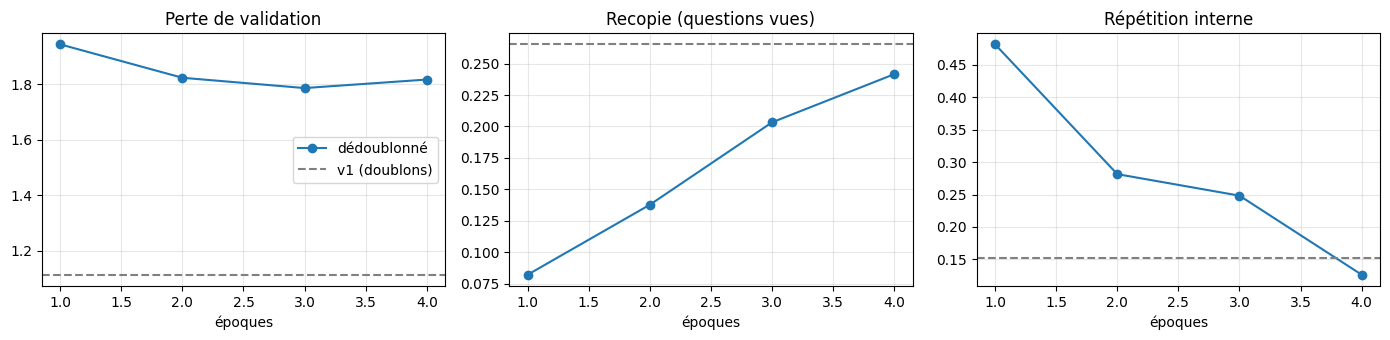

In [15]:
import pandas as pd, matplotlib.pyplot as plt
df = pd.DataFrame(tableau)
print(df.to_string(index=False, formatters={"perte val": "{:.3f}".format, "recopie vues": "{:.0%}".format,
      "recopie nouvelles": "{:.0%}".format, "répétition": "{:.0%}".format}))

d = df[df["modèle"].str.startswith("dédoublonné")]
v1 = df.iloc[0]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col, titre in [(axes[0], "perte val", "Perte de validation"),
                       (axes[1], "recopie vues", "Recopie (questions vues)"),
                       (axes[2], "répétition", "Répétition interne")]:
    ax.plot(range(1, len(d) + 1), d[col], marker="o", label="dédoublonné")
    ax.axhline(v1[col], ls="--", c="gray", label="v1 (doublons)")
    ax.set_title(titre); ax.set_xlabel("époques"); ax.grid(alpha=.3)
axes[0].legend()
plt.tight_layout(); plt.show()

## 5. Les réponses, époque par époque

Quelques questions nouvelles, pour voir **à l'œil** ce que disent les chiffres.

In [16]:
choix = ["Qu'est-ce que la photosynthèse ?", "Pourquoi le ciel est-il bleu ?",
         "Pourquoi faut-il dormir ?", "Qu'est-ce qu'un nombre premier ?",
         "Résume l'histoire de la Révolution française en deux phrases."]
for q in choix:
    i = nouvelles.index(q)
    print("❓", q)
    for nom, rep in reponses_par_modele.items():
        print(f"   {nom:<20}: {rep[i].replace(chr(10), ' / ')[:200]}")
    print()

❓ Qu'est-ce que la photosynthèse ?
   v1 (doublons, 2 ép.): La photosynthèse est le processus par lequel les plantes, les algues et certaines bactéries convertissent la lumière du soleil en énergie chimique pour produire leur propre nourriture.
   dédoublonné, 1 ép.  : La photosynthèse est un processus complexe qui se déroule dans les chloroplastes des cellules végétales. Les chloroplastes sont responsables de la photosynthèse, ce qui est essentiel à la survie des p
   dédoublonné, 2 ép.  : La photosynthèse est le processus par lequel les plantes, les algues et certaines bactéries convertissent la lumière du soleil en énergie chimique.
   dédoublonné, 3 ép.  : La photosynthèse est le processus par lequel les plantes, les algues et certaines bactéries convertissent la lumière du soleil en énergie chimique.
   dédoublonné, 4 ép.  : La photosynthèse est le processus par lequel les plantes, les algues et certaines bactéries convertissent la lumière en énergie chimique.

❓ Pourquoi le ciel 

## 6. Publier la meilleure époque (optionnel)

Choisis l'époque qui te paraît le meilleur compromis : bonne perte, recopie basse, peu de répétitions, réponses sensées. Mets son numéro dans `MEILLEURE` et lance la cellule. Elle remplace la version actuelle (v2) du dépôt ; l'historique garde les précédentes.

In [17]:
from dataclasses import asdict
import shutil

MEILLEURE = 2          # <- à choisir d'après le tableau

modele.load_state_dict(copies[MEILLEURE])
ligne = df[df["modèle"] == f"dédoublonné, {MEILLEURE} ép."].iloc[0]
SORTIE = f"{TRAVAIL}/instruct_v3"
os.makedirs(SORTIE, exist_ok=True)
save_model(modele.cpu(), f"{SORTIE}/model.safetensors"); modele.to(device)
json.dump(asdict(config), open(f"{SORTIE}/config.json", "w"), indent=2)
tokenizer.save(f"{SORTIE}/tokenizer.json")
shutil.copy(f"{TRAVAIL}/base/model.py", f"{SORTIE}/model.py")

lignes = "\n".join(f"| {r['modèle']} | {r['étapes']} | {r['perte val']:.3f} | {r['recopie vues']:.0%} | "
                   f"{r['recopie nouvelles']:.0%} | {r['répétition']:.0%} |" for r in tableau)
fiche = f"""---
language: fr
license: apache-2.0
library_name: pytorch
tags: [text-generation, gpt, from-scratch, french, sft]
base_model: {BASE}
datasets: [jpacifico/French-Alpaca-dataset-Instruct-110K]
---

# Petit GPT français — version instruct (SFT)

Version ajustée par SFT de [{BASE}](https://huggingface.co/{BASE}), un GPT de 46 M de paramètres entraîné de zéro sur Wikipédia en français.

## Données

French-Alpaca-dataset-Instruct-110K (Jonathan Pacifico, 2024), réponses générées par GPT-3.5-turbo.
Le jeu contient 51,7 % de doublons exacts et 55,7 % de quasi-doublons (même début de réponse sur 10 mots normalisés).
Dédoublonnage avant la séparation train / validation : {len(donnees):,} -> {len(exemples):,} exemples.

## Expérience : doublons, nombre d'époques et récitation

- **Recopie** : part des 8-grammes de mots des réponses générées (décodage glouton) présents tels quels dans le jeu d'entraînement.
- **Répétition** : part des 4-grammes répétés à l'intérieur d'une même réponse.
- Perte mesurée sur la validation dédoublonnée. Celle de la v1 est optimiste : la v1 a vu ces exemples pendant son entraînement.

| Modèle | Étapes | Perte val | Recopie (vues) | Recopie (nouvelles) | Répétition |
|---|---|---|---|---|---|
{lignes}

Version publiée : **dédoublonnée, {MEILLEURE} époque(s)**.

## Format

```
<|utilisateur|>
Ta question
<|assistant|>
```
La réponse se termine par `<|endoftext|>`.

## Limites

46 M de paramètres : connaissances très limitées, le modèle invente souvent. Projet d'apprentissage, pas un assistant fiable.
"""
open(f"{SORTIE}/README.md", "w", encoding="utf-8").write(fiche)
HfApi().upload_folder(folder_path=SORTIE, repo_id=INSTRUCT,
                      commit_message=f"v3 : dédoublonné, {MEILLEURE} époque(s)")
print(f"Mis à jour : https://huggingface.co/{INSTRUCT}")

Mis à jour : https://huggingface.co/Ezeck01/petit-gpt-fr-46m-instruct
